# Neutral Band and Side-Specific Jenks Classification

This notebook classifies the validated three-pillar `core_index_available` score. It does not alter the continuous index.

The design respects the substantive zero point:

1. choose a symmetric neutral band around zero;
2. distinguish neutral from hedging within that band using pillar disagreement;
3. run a two-class Jenks split separately on the China-oriented and US-oriented sides; and
4. fix the resulting thresholds across 2004-2024 rather than recalculating them every year.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt


def find_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "src/data/build_orientation_classification.py").exists():
            return candidate
    raise FileNotFoundError("Repository root not found")

ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.build_orientation_classification import (
    CHINA_STRONG_BREAK,
    NEUTRAL_HALF_WIDTH,
    US_STRONG_BREAK,
    apply_classification,
    generate_all_outputs,
)

OUT = ROOT / "outputs/tables/closeness_index"
index = pd.read_csv(OUT / "us_china_relative_orientation_index_country_year.csv")

# Regenerate the full auditable classification analysis from the canonical index.
# This writes the candidate-band, stability and classified-panel outputs used below.
classification_summary = generate_all_outputs(index, OUT)

metrics = pd.read_csv(OUT / "neutral_band_candidate_metrics.csv")
stability = pd.read_csv(OUT / "jenks_stability_summary.csv")


## Candidate neutral bands

Candidate half-widths from 0.025 to 0.15 are compared using class sizes, annual category changes, full side-to-side reversals and Jenks-break stability. A 0.05 half-width is selected because it leaves 13.1% of observations in the neutral or hedging band, retains meaningful directional classes and materially reduces full orientation reversals compared with 0.025.

In [2]:
metrics.merge(stability, on="neutral_half_width")

,neutral_half_width,china_strong_break_magnitude,us_strong_break,neutral_or_hedging_n,neutral_or_hedging_pct,moderately_china_n,strongly_china_n,moderately_us_n,strongly_us_n,smallest_directional_class_pct,...,category_changes,category_change_pct,full_orientation_reversals,full_reversal_pct,neutral_n,hedging_n,max_china_break_change,mean_china_break_change,max_us_break_change,mean_us_break_change
0,0.025,0.239246,0.254892,259,6.452417,1415,827,1106,407,10.139512,...,689,18.027211,74,1.936159,34,225,0.001955,0.000511,0.006061,0.002519
1,0.050,0.255087,0.270886,526,13.104136,1384,720,1020,364,9.068261,...,707,18.498168,25,0.654108,103,423,0.000889,0.000427,0.003614,0.001062
2,0.075,0.264537,0.284114,818,20.378675,1289,678,891,338,8.420528,...,708,18.524333,6,0.156986,212,606,0.001462,0.000228,0.003761,0.001538
3,0.100,0.290204,0.296806,1098,27.354260,1308,505,790,313,7.797708,...,720,18.838305,2,0.052329,342,756,0.003397,0.001878,0.002391,0.001044
4,0.125,0.318133,0.310141,1399,34.853014,1284,359,683,289,7.199801,...,666,17.425432,0,0.000000,520,879,0.002498,0.001120,0.004470,0.001366
5,0.150,0.331865,0.329386,1682,41.903338,1183,314,585,250,6.228201,...,631,16.509681,0,0.000000,775,907,0.001836,0.000417,0.005883,0.001787


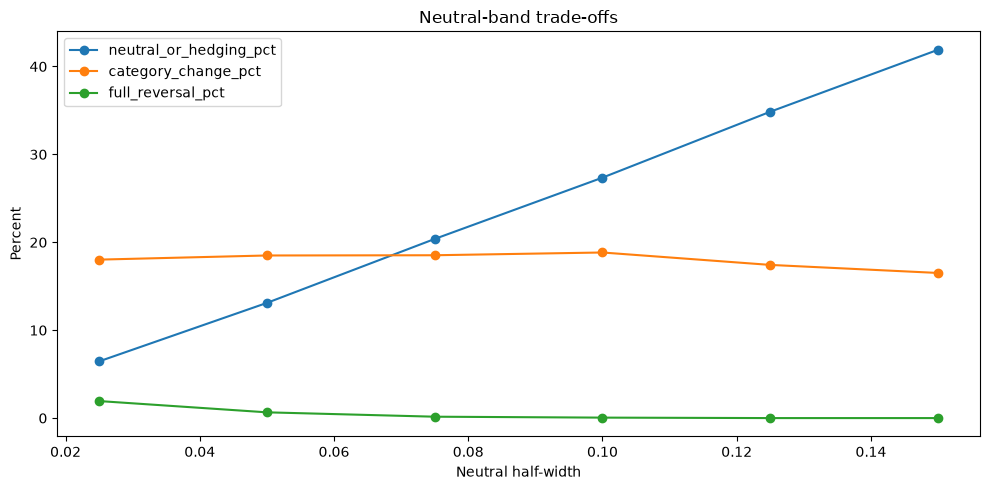

In [3]:
ax = metrics.plot(
    x="neutral_half_width",
    y=["neutral_or_hedging_pct", "category_change_pct", "full_reversal_pct"],
    marker="o",
    figsize=(10, 5),
)
ax.set(xlabel="Neutral half-width", ylabel="Percent", title="Neutral-band trade-offs")
plt.tight_layout()
plt.show()


## Fixed classification thresholds

The selected production thresholds are:

- strongly China-oriented: score at or below -0.255087;
- moderately China-oriented: above -0.255087 through -0.05;
- neutral or hedging: greater than -0.05 and less than +0.05;
- moderately US-oriented: +0.05 through below +0.270886;
- strongly US-oriented: +0.270886 or above.

The asymmetric strong-orientation breaks are empirical Jenks results. The neutral band remains symmetric because zero has substantive meaning.

In [4]:
classified = apply_classification(index)
classified["orientation_class"].value_counts()

orientation_class
moderately_china_oriented    1384
moderately_us_oriented       1020
strongly_china_oriented       720
neutral_or_hedging            526
strongly_us_oriented          364
Name: count, dtype: int64

In [5]:
classified.loc[
    classified.orientation_class.eq("neutral_or_hedging"), "neutral_type"
].value_counts()

neutral_type
hedging    423
neutral    103
Name: count, dtype: int64

## Stability

Leaving out any single year changes the China strong threshold by at most 0.000889 and the US threshold by at most 0.003614 for the selected neutral band. Thresholds are therefore fixed globally for 2004-2024 rather than re-estimated annually.

In [6]:
stability.loc[stability.neutral_half_width.eq(NEUTRAL_HALF_WIDTH)]

,neutral_half_width,max_china_break_change,mean_china_break_change,max_us_break_change,mean_us_break_change
1,0.05,0.000889,0.000427,0.003614,0.001062


## 2024 profile

In [7]:
classified.loc[classified.year.eq(2024), "orientation_class"].value_counts()

orientation_class
moderately_china_oriented    63
moderately_us_oriented       44
strongly_china_oriented      38
strongly_us_oriented         28
neutral_or_hedging           18
Name: count, dtype: int64

In [8]:
classified.loc[
    classified.year.eq(2024) & classified.orientation_class.eq("neutral_or_hedging"),
    "neutral_type",
].value_counts()

neutral_type
hedging    15
neutral     3
Name: count, dtype: int64

## Validation

In [9]:
assert not classified.duplicated(["country_iso3", "year"]).any()
assert classified.loc[classified.core_index_available.isna(), "orientation_class"].eq("no_score").all()
assert classified.loc[classified.core_index_available.abs().lt(0.05), "orientation_class"].eq("neutral_or_hedging").all()
assert classified.loc[classified.core_index_available.le(CHINA_STRONG_BREAK), "orientation_class"].eq("strongly_china_oriented").all()
assert classified.loc[classified.core_index_available.ge(US_STRONG_BREAK), "orientation_class"].eq("strongly_us_oriented").all()

pd.Series({
    "rows": len(classified),
    "neutral_half_width": NEUTRAL_HALF_WIDTH,
    "china_strong_break": CHINA_STRONG_BREAK,
    "us_strong_break": US_STRONG_BREAK,
    "neutral_or_hedging": classified.orientation_class.eq("neutral_or_hedging").sum(),
})


rows                  4014.000000
neutral_half_width       0.050000
china_strong_break      -0.255087
us_strong_break          0.270886
neutral_or_hedging     526.000000
dtype: float64